# Data Preparation

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data_cleaning/panel_weekly.csv")

print(df.shape)
print(df.head())
print(df.info())
df.columns

(4365, 11)
         week    commodity       ret    mom_4w   mom_12w   vol_12w    target  \
0  2010-01-01    crude_oil  0.016784  0.056464  0.112384  0.045818  0.042717   
1  2010-01-01         gold -0.008061 -0.064041  0.047588  0.024435  0.039262   
2  2010-01-01       copper  0.017273  0.036664  0.168475  0.030087  0.018182   
3  2010-01-01  natural_gas -0.012582  0.209087  0.197335  0.087556  0.031766   
4  2010-01-01        wheat  0.032412  0.010031  0.163318  0.054906  0.049861   

   net_tone  n_relevant  has_news  attention  
0       0.0         0.0         0        0.0  
1       0.0         0.0         0        0.0  
2       0.0         0.0         0        0.0  
3       0.0         0.0         0        0.0  
4       0.0         0.0         0        0.0  
<class 'pandas.DataFrame'>
RangeIndex: 4365 entries, 0 to 4364
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   week        4365 non-null   str    
 1   co

Index(['week', 'commodity', 'ret', 'mom_4w', 'mom_12w', 'vol_12w', 'target',
       'net_tone', 'n_relevant', 'has_news', 'attention'],
      dtype='str')

In [3]:
# 1. Vérifier les valeurs manquantes
print("Valeurs manquantes :")
print(df.isnull().sum())

# 2. Vérifier les doublons
print("\nDoublons :", df.duplicated().sum())

# 3. Vérifier qu'il n'existe qu'une observation
# par matière première et par semaine
print(
    "\nDoublons week + commodity :",
    df.duplicated(subset=["week", "commodity"]).sum()
)

# 4. Statistiques descriptives
print("\nStatistiques descriptives :")
display(df.describe())

# 5. Vérifier les périodes couvertes
print("\nPremière semaine :", df["week"].min())
print("Dernière semaine :", df["week"].max())

Valeurs manquantes :
week          0
commodity     0
ret           0
mom_4w        0
mom_12w       0
vol_12w       0
target        0
net_tone      0
n_relevant    0
has_news      0
attention     0
dtype: int64

Doublons : 0

Doublons week + commodity : 0

Statistiques descriptives :


,ret,mom_4w,mom_12w,vol_12w,target,net_tone,n_relevant,has_news,attention
count,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000,4365.000000
mean,0.001686,0.006809,0.020141,0.042286,0.001674,0.018959,2.862772,0.536999,0.752098
std,0.050091,0.096042,0.158501,0.027660,0.050126,0.458186,11.220693,0.498686,0.884284
min,-0.293098,-0.763677,-1.022311,0.007624,-0.293098,-1.000000,0.000000,0.000000,0.000000
25%,-0.022130,-0.040647,-0.058624,0.024308,-0.022136,0.000000,0.000000,0.000000,0.000000
50%,0.001166,0.004922,0.016250,0.035090,0.001160,0.000000,1.000000,1.000000,0.693147
75%,0.023610,0.053251,0.094552,0.051270,0.023610,0.166667,3.000000,1.000000,1.386294
max,0.699968,0.737780,0.955557,0.249565,0.699968,1.000000,401.000000,1.000000,5.996452



Première semaine : 2010-01-01
Dernière semaine : 2026-09-18


In [4]:
# Conversion des dates
df["week"] = pd.to_datetime(df["week"])

# Rendements extrêmes (> 30 % ou < -30 %)
extreme_returns = df[
    (df["ret"].abs() > 0.30) |
    (df["target"].abs() > 0.30)
]

print("Nombre de rendements extrêmes :",
      len(extreme_returns))

display(
    extreme_returns[
        ["week", "commodity", "ret", "target"]
    ].sort_values("week")
)

# Semaines ayant plus de 100 articles pertinents
extreme_news = df[df["n_relevant"] > 100]

print("\nObservations avec plus de 100 articles :",
      len(extreme_news))

display(
    extreme_news[
        ["week", "commodity", "n_relevant", "net_tone"]
    ].sort_values("n_relevant", ascending=False)
)

Nombre de rendements extrêmes : 10


,week,commodity,ret,target
2670,2020-03-27,crude_oil,-0.041016,0.317527
2675,2020-04-03,crude_oil,0.317527,-0.196895
3174,2022-02-25,wheat,0.057716,0.599051
3179,2022-03-04,wheat,0.599051,-0.191395
3738,2024-04-26,natural_gas,-0.078767,0.327138
3743,2024-05-03,natural_gas,0.327138,0.051354
4188,2026-01-16,natural_gas,-0.020827,0.699968
4193,2026-01-23,natural_gas,0.699968,-0.174597
4215,2026-02-27,crude_oil,0.009489,0.356312
4220,2026-03-06,crude_oil,0.356312,0.085919



Observations avec plus de 100 articles : 12


,week,commodity,n_relevant,net_tone
4225,2026-03-13,crude_oil,401.0,0.590524
4220,2026-03-06,crude_oil,220.0,0.793636
4265,2026-05-08,crude_oil,191.0,-0.249215
4295,2026-06-19,crude_oil,184.0,-0.616848
4230,2026-03-20,crude_oil,160.0,0.565625
4320,2026-07-24,crude_oil,159.0,0.594969
4310,2026-07-10,crude_oil,132.0,0.328030
4315,2026-07-17,crude_oil,127.0,0.638583
4270,2026-05-15,crude_oil,121.0,0.468595
4260,2026-05-01,crude_oil,118.0,0.486441


In [5]:
# Vérification de la couverture des actualités

df["week"] = pd.to_datetime(df["week"])
df["year"] = df["week"].dt.year

coverage = df.groupby(
    ["year", "commodity"]
).agg(
    weeks=("week", "nunique"),
    weeks_with_news=("has_news", "sum"),
    total_articles=("n_relevant", "sum"),
    max_articles=("n_relevant", "max")
).reset_index()

# Pourcentage de semaines avec actualités
coverage["coverage_pct"] = (
    100 * coverage["weeks_with_news"]
    / coverage["weeks"]
).round(2)

# Tableau de comparaison entre années
coverage_table = coverage.pivot(
    index="year",
    columns="commodity",
    values="coverage_pct"
)

display(coverage_table)

commodity,copper,crude_oil,gold,natural_gas,wheat
year,,,,,
2010,32.08,32.08,86.79,3.77,1.89
2011,48.08,46.15,86.54,15.38,7.69
2012,42.31,32.69,80.77,5.77,0.00
2013,38.46,34.62,88.46,9.62,0.00
2014,26.92,38.46,86.54,3.85,0.00
2015,36.54,65.38,82.69,13.46,1.92
2016,39.62,60.38,98.11,9.43,1.89
2017,78.85,67.31,100.00,7.69,11.54
2018,59.62,96.15,98.08,94.23,50.00


In [6]:


# 1. Convertir les dates
df["week"] = pd.to_datetime(df["week"])

# 2. Trier les données chronologiquement
df = df.sort_values(["week", "commodity"]).copy()

# 3. Date correspondant au rendement à prédire
df["target_week"] = df["week"] + pd.Timedelta(days=7)

print(df.head())

# 4. Séparation chronologique
train = df[df["target_week"] < "2021-01-01"].copy()

val = df[
    (df["week"] >= "2021-01-01") &
    (df["target_week"] < "2024-01-01")
].copy()

test = df[df["week"] >= "2024-01-01"].copy()

# 5. Afficher les résultats
print("Train :", train.shape)
print("Validation :", val.shape)
print("Test :", test.shape)

print("\nPériode Train :", train["week"].min(), train["week"].max())
print("Période Validation :", val["week"].min(), val["week"].max())
print("Période Test :", test["week"].min(), test["week"].max())

        week    commodity       ret    mom_4w   mom_12w   vol_12w    target  \
2 2010-01-01       copper  0.017273  0.036664  0.168475  0.030087  0.018182   
0 2010-01-01    crude_oil  0.016784  0.056464  0.112384  0.045818  0.042717   
1 2010-01-01         gold -0.008061 -0.064041  0.047588  0.024435  0.039262   
3 2010-01-01  natural_gas -0.012582  0.209087  0.197335  0.087556  0.031766   
4 2010-01-01        wheat  0.032412  0.010031  0.163318  0.054906  0.049861   

   net_tone  n_relevant  has_news  attention  year target_week  
2       0.0         0.0         0        0.0  2010  2010-01-08  
0       0.0         0.0         0        0.0  2010  2010-01-08  
1       0.0         0.0         0        0.0  2010  2010-01-08  
3       0.0         0.0         0        0.0  2010  2010-01-08  
4       0.0         0.0         0        0.0  2010  2010-01-08  
Train : (2865, 13)
Validation : (780, 13)
Test : (710, 13)

Période Train : 2010-01-01 00:00:00 2020-12-18 00:00:00
Période Validation 

# Modèles par matière première

Un modèle est estimé **séparément pour chaque matière première**. Pour chaque
couple (modèle, jeu de variables), les prévisions sont rassemblées dans une
matrice `semaines × matières premières` : un vecteur de rendements prévus par
matière première. Cette matrice est l'entrée de l'étape portefeuille.

Deux jeux de variables sont comparés, à modèle et fenêtre identiques :

| Jeu | Variables |
|---|---|
| A : prix | `ret`, `mom_4w`, `mom_12w`, `vol_12w` |
| B : prix + news | les mêmes + `net_tone`, `n_relevant`, `has_news`, `attention` |

## Configuration

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

PRICE = ["ret", "mom_4w", "mom_12w", "vol_12w"]
NEWS = ["net_tone", "n_relevant", "has_news", "attention"]

FEATURE_SETS = {
    "A: price": PRICE,
    "B: price+news": PRICE + NEWS,
}

COMS = sorted(df["commodity"].unique())
TARGET = "target"

print("Matières premières :", COMS)
print("Jeux de variables  :", list(FEATURE_SETS))

Matières premières : ['copper', 'crude_oil', 'gold', 'natural_gas', 'wheat']
Jeux de variables  : ['A: price', 'B: price+news']


## Modèles

`RidgeCV` choisit la pénalité par validation croisée temporelle sur le train
uniquement. Les arbres sont volontairement contraints : chaque modèle n'est
estimé que sur les observations d'une seule matière première.

In [8]:
def make_models(seed=42):
    return {
        "Ridge": RidgeCV(
            alphas=np.logspace(-2, 5, 40),
            cv=TimeSeriesSplit(5)
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=3,
            min_samples_leaf=30,
            random_state=seed,
            n_jobs=-1
        ),
        "LightGBM": LGBMRegressor(
            n_estimators=150,
            learning_rate=0.02,
            max_depth=3,
            num_leaves=5,
            min_child_samples=30,
            reg_lambda=5.0,
            random_state=seed,
            n_jobs=-1,
            verbosity=-1
        ),
    }

print("Modèles :", list(make_models()))

Modèles : ['Ridge', 'Random Forest', 'LightGBM']


## Métriques

`R2_oos` est calculé par rapport à la moyenne du train **de la matière première
concernée** (convention de Campbell-Thompson), et non par rapport à la moyenne
de l'échantillon de validation. `IC_t` est la statistique de Student de l'IC :
avec environ 156 semaines, un IC doit dépasser 0,16 en valeur absolue pour
sortir du bruit.

In [ ]:
def evaluate(y_true, y_pred, benchmark):
    #benchmark : the mean of that commodity’s training returns
    y = np.asarray(y_true)
    p = np.asarray(y_pred)
    n = len(y)

    ic = np.corrcoef(y, p)[0, 1] if np.std(p) > 1e-12 else 0.0
    ic_t = ic * np.sqrt(n - 2) / np.sqrt(max(1 - ic ** 2, 1e-12))

    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": np.sqrt(mean_squared_error(y, p)),
        "R2_oos": 1 - ((y - p) ** 2).sum() / ((y - benchmark) ** 2).sum(),
        "DirAcc": np.mean((y > 0) == (p > 0)),
        "IC": ic,
        "IC_t": ic_t,
        "n": n,
    }

## Estimation : une boucle par matière première

Pour chaque matière première, chaque jeu de variables et chaque modèle :
estimation sur le train, prévision sur la validation, et stockage de la
prévision dans la colonne correspondante de la matrice `ALPHA`.

In [ ]:
# Rendements réalisés : semaines x matières premières
RET = (val.pivot(index="week", columns="commodity", values=TARGET)
          .sort_index()) #passer une table du format long au format large

#print(type(RET),RET.head())

# Une matrice de prévisions par (modèle, jeu de variables)
ALPHA = {
    (mdl_name, fs_name): pd.DataFrame(index=RET.index, columns=COMS, dtype=float)
    for fs_name in FEATURE_SETS # Models A and B (price and price + news)
    for mdl_name in make_models() # ML models (ridge, random forest, lightbtm)
}

rows = [] # Predictions from the baseline
ridge_alphas = []

# For each commodity : COMS =[all commodities]
for com in COMS:

    tr = train[train["commodity"] == com]
    va = val[val["commodity"] == com].sort_values("week") 

    y_tr = tr[TARGET]
    y_va = va[TARGET]

    # Baseline : moyenne du train de cette matière première
    benchmark = np.full(len(y_va), y_tr.mean())

    m = evaluate(y_va, benchmark, benchmark) # Function coded give the dictionary (metric:error)
    m.update(commodity=com, model="Baseline", features="—") # add this in m : "commodity": com, "model": model, "features": "e.g B: price+news"
    rows.append(m)

    for fs_name, feats in FEATURE_SETS.items():
        for mdl_name, mdl in make_models().items():

            pipe = Pipeline([
                ("scaler", StandardScaler()),
                ("model", mdl)
            ]).fit(tr[feats], y_tr)

            y_pred = pipe.predict(va[feats])

            # Vecteur de rendements prévus pour cette matière première
            ALPHA[(mdl_name, fs_name)].loc[va["week"].values, com] = y_pred

            m = evaluate(y_va, y_pred, benchmark)
            m.update(commodity=com, model=mdl_name, features=fs_name)
            rows.append(m)

            if mdl_name == "Ridge":
                ridge_alphas.append({
                    "commodity": com,
                    "features": fs_name,
                    "alpha": pipe.named_steps["model"].alpha_
                })

results = (pd.DataFrame(rows)
             .set_index(["commodity", "model", "features"])
             [["MAE", "RMSE", "R2_oos", "DirAcc", "IC", "IC_t", "n"]])

print("Modèles estimés :", len(COMS) * len(FEATURE_SETS) * len(make_models()))

<class 'pandas.DataFrame'> commodity     copper  crude_oil      gold  natural_gas     wheat
week                                                            
2021-01-01  0.045390   0.076669 -0.031502     0.063411 -0.002732
2021-01-08 -0.019192   0.002297 -0.002997     0.013704  0.057534
2021-01-15  0.009020  -0.001719  0.014372    -0.106321 -0.060696
2021-01-22 -0.017054  -0.001339 -0.004795     0.048242  0.044917
2021-01-29  0.018329   0.089080 -0.018568     0.116615 -0.032805
Modèles estimés : 30


## Performances, matière première par matière première

In [11]:
display(results.round(4))

MAE    RMSE  R2_oos  DirAcc  \
commodity   model         features                                        
copper      Baseline      —              0.0261  0.0340  0.0000  0.5321   
            Ridge         A: price       0.0260  0.0339  0.0012  0.5641   
            Random Forest A: price       0.0264  0.0342 -0.0126  0.4808   
            LightGBM      A: price       0.0269  0.0347 -0.0463  0.4744   
            Ridge         B: price+news  0.0260  0.0339  0.0008  0.5449   
            Random Forest B: price+news  0.0264  0.0341 -0.0114  0.4872   
            LightGBM      B: price+news  0.0268  0.0348 -0.0480  0.5256   
crude_oil   Baseline      —              0.0399  0.0536  0.0000  0.5577   
            Ridge         A: price       0.0398  0.0545 -0.0353  0.5833   
            Random Forest A: price       0.0403  0.0552 -0.0602  0.5192   
            LightGBM      A: price       0.0405  0.0556 -0.0782  0.5385   
            Ridge         B: price+news  0.0403  0.0546 -0.0371  0.5192   
            Random Forest B: price+news  0.0404  0.0552 -0.0624  0.5321   
            LightGBM      B: price+news  0.0406  0.0559 -0.0868  0.5064   
gold        Baseline      —              0.0146  0.0191  0.0000  0.5513   
            Ridge         A: price       0.0146  0.0191  0.0001  0.5513   
            Random Forest A: price       0.0145  0.0191  0.0073  0.5449   
            LightGBM      A: price       0.0145  0.0191 -0.0011  0.5064   
            Ridge         B: price+news  0.0146  0.0191  0.0002  0.5513   
            Random Forest B: price+news  0.0145  0.0190  0.0148  0.5449   
            LightGBM      B: price+news  0.0144  0.0190  0.0091  0.5705   
natural_gas Baseline      —              0.0699  0.0891  0.0000  0.5000   
            Ridge         A: price       0.0700  0.0893 -0.0051  0.4679   
            Random Forest A: price       0.0713  0.0908 -0.0398  0.4679   
            LightGBM      A: price       0.0721  0.0921 -0.0682  0.4808   
            Ridge         B: price+news  0.0701  0.0892 -0.0035  0.5000   
            Random Forest B: price+news  0.0713  0.0908 -0.0388  0.4808   
            LightGBM      B: price+news  0.0721  0.0921 -0.0685  0.4808   
wheat       Baseline      —              0.0408  0.0679  0.0000  0.4872   
            Ridge         A: price       0.0406  0.0684 -0.0153  0.5449   
            Random Forest A: price       0.0405  0.0680 -0.0032  0.5833   
            LightGBM      A: price       0.0404  0.0683 -0.0125  0.6090   
            Ridge         B: price+news  0.0406  0.0679 -0.0000  0.5256   
            Random Forest B: price+news  0.0405  0.0680 -0.0033  0.5769   
            LightGBM      B: price+news  0.0404  0.0683 -0.0125  0.6090   

                                             IC    IC_t    n  
commodity   model         features                            
copper      Baseline      —              0.0000  0.0000  156  
            Ridge         A: price       0.0377  0.4687  156  
            Random Forest A: price       0.0100  0.1236  156  
            LightGBM      A: price      -0.0062 -0.0776  156  
            Ridge         B: price+news  0.0423  0.5259  156  
            Random Forest B: price+news  0.0117  0.1451  156  
            LightGBM      B: price+news -0.0018 -0.0225  156  
crude_oil   Baseline      —              0.0000  0.0000  156  
            Ridge         A: price      -0.0705 -0.8774  156  
            Random Forest A: price      -0.0648 -0.8053  156  
            LightGBM      A: price      -0.0550 -0.6836  156  
            Ridge         B: price+news -0.0570 -0.7086  156  
            Random Forest B: price+news -0.0667 -0.8294  156  
            LightGBM      B: price+news -0.0598 -0.7437  156  
gold        Baseline      —              0.0000  0.0000  156  
            Ridge         A: price       0.0973  1.2131  156  
            Random Forest A: price       0.0876  1.0914  156  
            LightGBM      A: price       0.0718  0.8927  156  
        

α contrôle la force du rétrécissement des coefficients. RidgeCV le choisit dans np.logspace(-2, 5, 40), donc entre 0,01 et 100 000.

α petit : la CV estime que les variables apportent de l’information, les coefficients restent grands, les prévisions varient.
α = 100 000 (le haut de la grille) : la CV a écrasé tous les coefficients. Le modèle prédit essentiellement la constante. Il n’a trouvé aucune relation stable sur le train.

In [12]:
# Pénalité Ridge retenue par validation croisée.
# Une valeur en haut de la grille signifie que le modèle est
# ramené vers la moyenne : aucun signal exploitable.

display(
    pd.DataFrame(ridge_alphas)
      .pivot(index="commodity", columns="features", values="alpha")
)

features,A: price,B: price+news
commodity,,
copper,2424.462017,5541.020330
crude_oil,203.091762,307.029063
gold,100000.000000,100000.000000
natural_gas,1060.818355,2424.462017
wheat,203.091762,1603.718744


## Information coefficient

Seule métrique qui sépare réellement les modèles : MAE et RMSE sont dominées
par la variance non prévisible des rendements hebdomadaires.

IC is the strength, and specifically the linear strength. It’s a correlation, so it only sees co-movement that’s proportional. If the model were right about direction but systematically wrong about magnitude, IC would still be high — correlation is scale-free. And if the relationship were genuinely non-linear, IC could be near zero while the forecast still contained information.
IC measures how strong my predictions is correlated to the real value and t how sure.

In [13]:
ic_table = (results.reset_index()
                   .query("model != 'Baseline'")
                   .pivot_table(index="commodity",
                                columns=["model", "features"],
                                values="IC"))

SE = 2 / np.sqrt(results["n"].max())

print(f"Bande de bruit : |IC| < {SE:.3f}  (2 écarts-types)")
display(ic_table.round(3))

Bande de bruit : |IC| < 0.160  (2 écarts-types)


model       LightGBM               Random Forest                  Ridge  \
features    A: price B: price+news      A: price B: price+news A: price   
commodity                                                                 
copper        -0.006        -0.002         0.010         0.012    0.038   
crude_oil     -0.055        -0.060        -0.065        -0.067   -0.071   
gold           0.072         0.110         0.088         0.128    0.097   
natural_gas   -0.105        -0.112        -0.127        -0.123   -0.025   
wheat          0.021         0.021         0.044         0.044   -0.034   

model                      
features    B: price+news  
commodity                  
copper              0.042  
crude_oil          -0.057  
gold                0.055  
natural_gas        -0.044  
wheat               0.009

In [14]:
# Apport des news, à modèle et fenêtre identiques

gain = (ic_table.xs("B: price+news", level=1, axis=1)
        - ic_table.xs("A: price", level=1, axis=1))

display(gain.round(3).style.background_gradient(axis=None, cmap="RdYlGn"))

model,LightGBM,Random Forest,Ridge
commodity,,,
copper,0.004000,0.002000,0.005000
crude_oil,-0.005000,-0.002000,0.014000
gold,0.038000,0.040000,-0.042000
natural_gas,-0.007000,0.005000,-0.019000
wheat,0.000000,-0.001000,0.044000


## Vecteurs de rendements prévus

Pour chaque couple (modèle, jeu de variables), une matrice
`semaines × matières premières`. `RET` contient les rendements réalisés sur la
même grille, ce qui permet d'écrire directement `pnl = (h * RET).sum(axis=1)`
à l'étape portefeuille.

In [15]:
A = ALPHA[("Ridge", "B: price+news")]

print("Dimensions :", A.shape)
print("Valeurs manquantes :", int(A.isna().sum().sum()))
display(A.head())

# Dispersion des prévisions : une colonne quasi constante
# produira des positions dégénérées à l'étape portefeuille.
display(A.std().rename("écart-type des prévisions").to_frame().T.round(5))

Dimensions : (156, 5)
Valeurs manquantes : 0


,copper,crude_oil,gold,natural_gas,wheat
week,,,,,
2021-01-01,0.000447,-0.001247,0.001216,0.001210,-0.000083
2021-01-08,0.000182,0.003196,0.001181,0.000926,0.000441
2021-01-15,0.000463,0.003119,0.001229,0.000115,-0.000161
2021-01-22,0.000211,-0.007479,0.001223,0.001515,0.000180
2021-01-29,0.000381,-0.007261,0.001213,0.001613,0.000478


,copper,crude_oil,gold,natural_gas,wheat
écart-type des prévisions,0.00034,0.00685,0.00002,0.00253,0.00166


## Graphiques

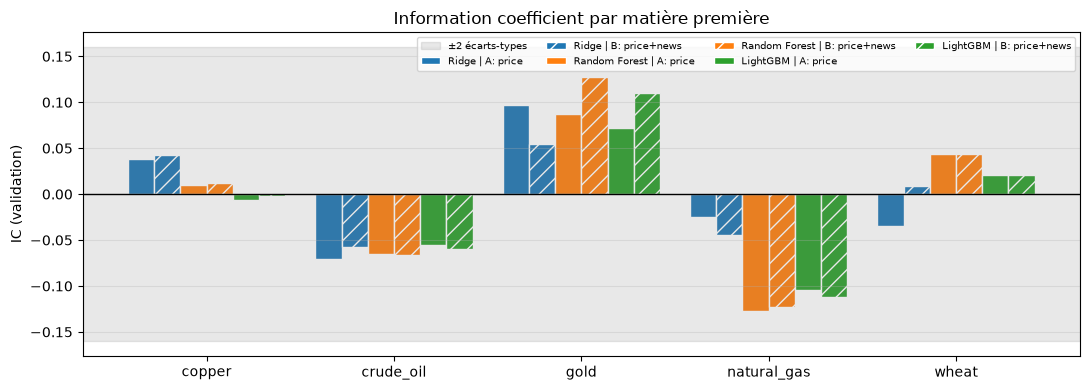

In [20]:
COLORS = {"Ridge": "C0", "Random Forest": "C1", "LightGBM": "C2"}
HATCH = {"A: price": "", "B: price+news": "//"}

fig, ax = plt.subplots(figsize=(11, 4))

x = np.arange(len(COMS))
width = 0.14

for i, (mdl_name, fs_name) in enumerate(
        [(m, f) for m in COLORS for f in HATCH]):

    values = [results.loc[(c, mdl_name, fs_name), "IC"] for c in COMS]

    ax.bar(x + (i - 2.5) * width, values, width,
           color=COLORS[mdl_name], hatch=HATCH[fs_name],
           edgecolor="white", label=f"{mdl_name} | {fs_name}")

ax.axhline(0, color="k", lw=1)
ax.axhspan(-SE, SE, color="grey", alpha=0.18, label="±2 écarts-types")
ax.set_xticks(x)
ax.set_xticklabels(COMS)
ax.set_ylabel("IC (validation)")
ax.set_title("Information coefficient par matière première")
ax.legend(fontsize=7, ncol=4)
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## PnL de diagnostic

Le PnL ci-dessous **n'est pas un backtest** : c'est un diagnostic visuel du
signal, matière première par matière première. La position suit une règle ad hoc
— signe de la prévision, taille proportionnelle à son amplitude (plafonnée à 3×) —
et le PnL est le cumul de `position × rendement réalisé` durant toute la validation, brut de coûts.

$$\text{pos}_t = \text{sign}(\hat r_t)\;\min\!\left(\frac{|\hat r_t|}{\overline{|\hat r|}},\,3\right)$$

Ni covariance, ni contraintes, ni coûts, ni positions précédentes. Le portefeuille
transversal avec optimisation dynamique vient à l'étape 7 ; cette courbe lui
servira de référence naïve.

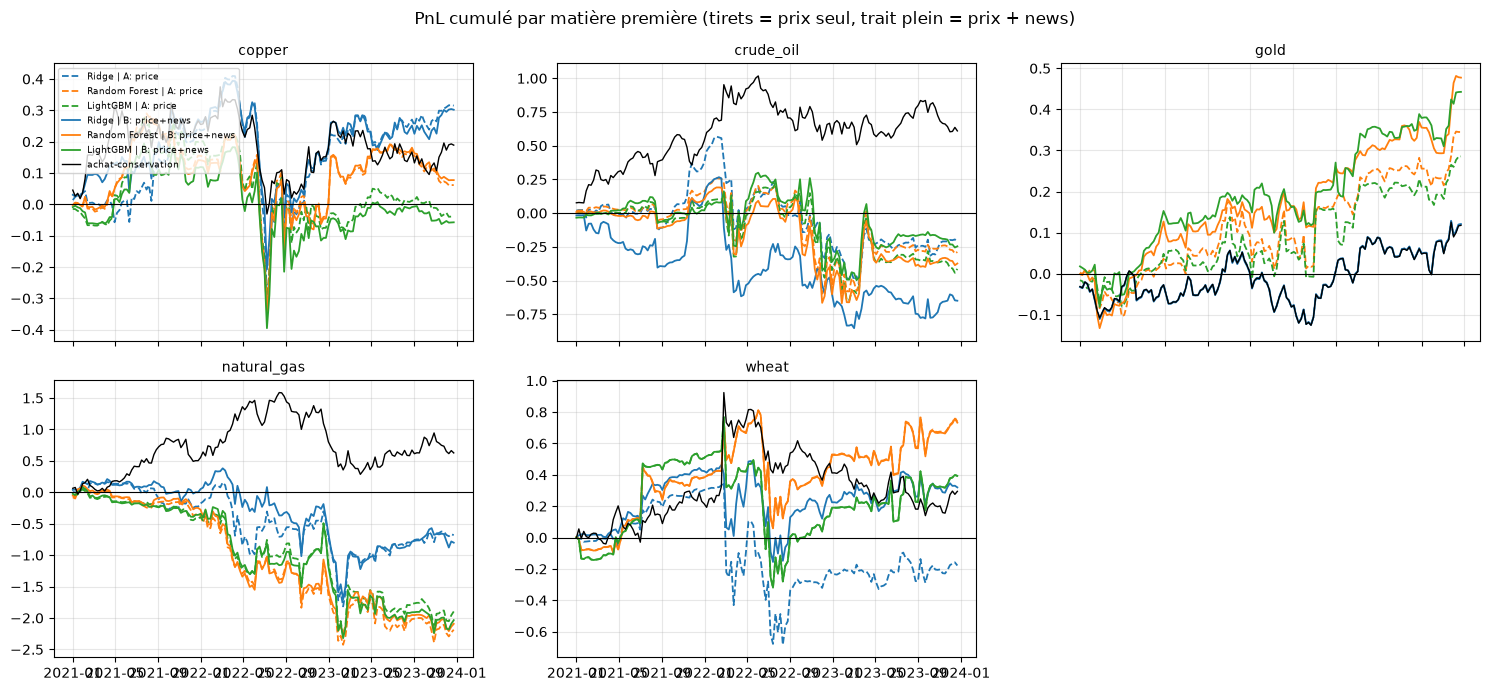

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)

for ax, com in zip(axes.ravel(), COMS):

    for (mdl_name, fs_name), A in ALPHA.items():

        # Position = signe de la prévision, taille proportionnelle
        # à son amplitude (plafonnée)
        pos = np.sign(A[com]) * (A[com].abs() / A[com].abs().mean()).clip(0, 3)

        ax.plot(RET.index, (pos * RET[com]).cumsum(),
                color=COLORS[mdl_name],
                ls="--" if fs_name == "A: price" else "-",
                lw=1.3, label=f"{mdl_name} | {fs_name}")

    ax.plot(RET.index, RET[com].cumsum(), color="k", lw=1, label="achat-conservation")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(com, fontsize=10)
    ax.grid(alpha=0.3)

axes.ravel()[-1].axis("off")
axes.ravel()[0].legend(fontsize=6.5, loc="upper left")

fig.suptitle("PnL cumulé par matière première "
             "(tirets = prix seul, trait plein = prix + news)")
fig.tight_layout()
plt.show()

## Lecture

- Les prévisions sont beaucoup moins volatiles que les rendements : c'est
  normal. Pour un IC de $\rho$, la prévision optimale a un écart-type de
  $\rho\,\sigma(r)$.
- $R^2_{oos} \approx 2\rho k - k^2$ avec $k = \sigma(\hat r)/\sigma(r)$ :
  une prévision qui varie sans corréler avec les rendements perd
  mécaniquement contre la baseline.
- Le PnL ci-dessus est brut de coûts et calculé matière première par matière
  première. Le portefeuille de l'étape 7 est transversal et intègre les coûts
  de transaction et les positions précédentes.

# COmputation of the portfolio : Dynamic optimization (Transaction cost)  